In [1]:
import zipfile
from pathlib import Path

DATA = Path("../data")

# Dataverse zip'i bazen içinde bir zip daha barındırıyor, hepsini açıyoruz
for _ in range(2):
    for z in DATA.rglob("*.zip"):
        out = z.with_suffix("")
        if not out.exists():
            print("Açılıyor:", z.name)
            zipfile.ZipFile(z).extractall(out)

for p in sorted(DATA.rglob("events/*.csv")):
    print(p.name)

Açılıyor: dataverse_files.zip
IC40_exp.csv
IC59_exp.csv
IC79_exp.csv
IC86_I_exp.csv
IC86_II_exp.csv
IC86_III_exp.csv
IC86_IV_exp.csv
IC86_V_exp.csv
IC86_VI_exp.csv
IC86_VII_exp.csv


In [2]:
import numpy as np
import pandas as pd

cols = ['mjd', 'logE', 'angErr', 'ra', 'dec', 'az', 'zen']
dfs = []
for f in sorted(DATA.rglob("events/*.csv")):
    d = pd.read_csv(f, sep=r'\s+', comment='#', header=None, names=cols)
    d['season'] = f.stem.replace('_exp', '')
    dfs.append(d)

ev = pd.concat(dfs, ignore_index=True)
print(f"Toplam olay: {len(ev):,}")
print(ev.groupby('season').size())
ev.describe()

Toplam olay: 1,134,450
season
IC40         36900
IC59        107011
IC79         93133
IC86_I      136244
IC86_II     112858
IC86_III    122541
IC86_IV     127045
IC86_V      129311
IC86_VI     123657
IC86_VII    145750
dtype: int64


,mjd,logE,angErr,ra,dec,az,zen
count,1.134450e+06,1.134450e+06,1.134450e+06,1.134450e+06,1.134450e+06,1.134450e+06,1.134450e+06
mean,5.663260e+04,3.726258e+00,8.507592e-01,1.798999e+02,3.395560e+00,1.790718e+02,9.339568e+01
std,9.943157e+02,9.846252e-01,9.372278e-01,1.039954e+02,3.521732e+01,1.044908e+02,3.521736e+01
min,5.456238e+04,1.050000e+00,2.000000e-01,0.000000e+00,-8.995700e+01,0.000000e+00,0.000000e+00
25%,5.581732e+04,2.960000e+00,3.100000e-01,8.970925e+01,-2.108000e+01,8.735600e+01,6.892000e+01
50%,5.665781e+04,3.250000e+00,5.800000e-01,1.797990e+02,5.666000e+00,1.803320e+02,9.566400e+01
75%,5.748708e+04,4.660000e+00,1.030000e+00,2.699600e+02,2.719100e+01,2.687280e+02,1.171920e+02
max,5.830797e+04,7.530000e+00,1.500000e+01,3.600000e+02,8.997700e+01,3.600000e+02,1.800000e+02


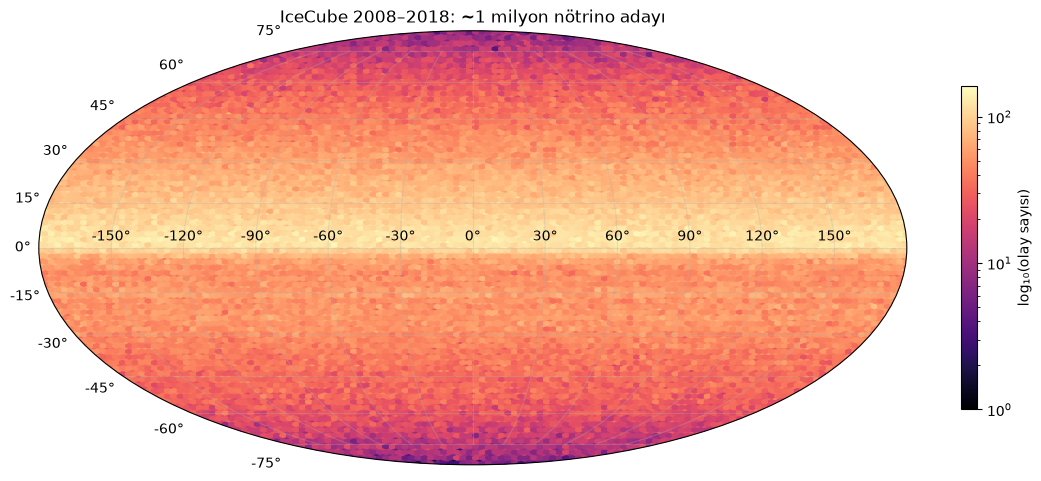

In [3]:
import matplotlib.pyplot as plt

ra  = np.radians(ev['ra'].values)
dec = np.radians(ev['dec'].values)

fig = plt.figure(figsize=(14, 7))
ax = fig.add_subplot(111, projection='mollweide')
hb = ax.hexbin(-(ra - np.pi), dec, gridsize=150, bins='log', cmap='magma')
fig.colorbar(hb, ax=ax, label='log₁₀(olay sayısı)', shrink=0.6)
ax.set_title('IceCube 2008–2018: ~1 milyon nötrino adayı')
ax.grid(alpha=0.3)
plt.savefig('../results/gok_haritasi.png', dpi=150, bbox_inches='tight')
plt.show()

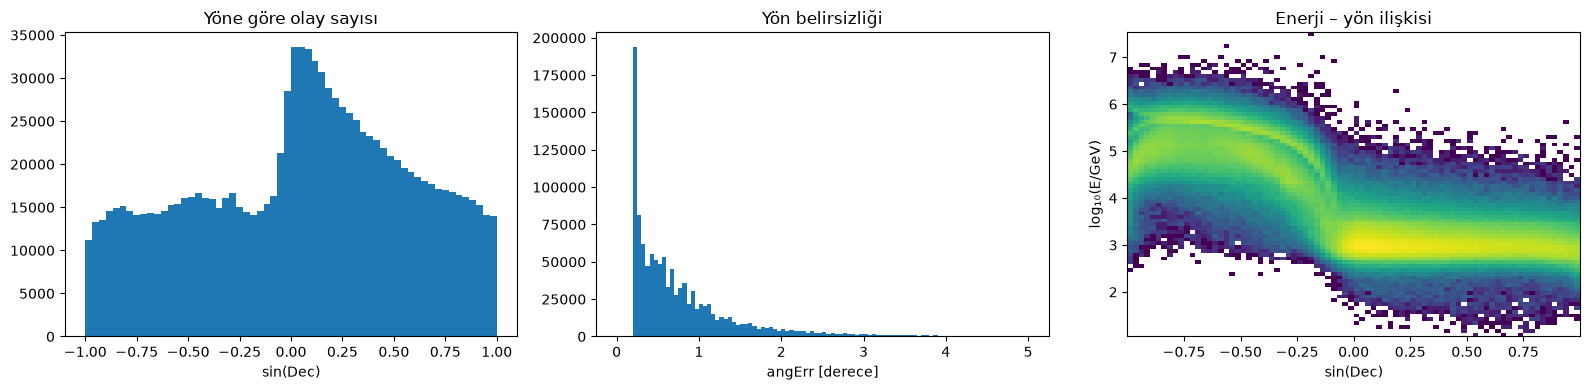

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4))

axs[0].hist(np.sin(dec), bins=60)
axs[0].set_xlabel('sin(Dec)'); axs[0].set_title('Yöne göre olay sayısı')

axs[1].hist(ev['angErr'], bins=100, range=(0, 5))
axs[1].set_xlabel('angErr [derece]'); axs[1].set_title('Yön belirsizliği')

axs[2].hist2d(np.sin(dec), ev['logE'], bins=80, cmap='viridis', norm='log')
axs[2].set_xlabel('sin(Dec)'); axs[2].set_ylabel('log₁₀(E/GeV)')
axs[2].set_title('Enerji – yön ilişkisi')

plt.tight_layout()
plt.savefig('../results/dagilimlar.png', dpi=150)
plt.show()